In [ ]:
from ps_func import initialize, run_iteration, set_soil_parameters, initialize_logs
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
import shutil

# Defining parameter sets

In [106]:
run_name = 'ps'
# initializes logs (only run if willing to override existing logs for run_name)
### initialize_logs(run_name)

In [112]:
# define waterlevel and dredging level ranges
wl_lo = -2.5
wl_hi = 4.5

d_level_lo = -24
d_level_hi = -20

params = pd.DataFrame(columns=['wl', 'd_level'])
i_0 = 0

# define new lists for water levels and dredging levels
range_wl = np.arange(wl_lo, wl_hi+2, 1)
range_d_level = np.arange(d_level_lo, d_level_hi+1, 1)
print(range_wl, range_d_level)

for d_level in range_d_level:
    for wl in range_wl:
        # Perform calculations or function calls with wl and d_level
        params.loc[i_0] = [wl, d_level]
        i_0 += 1

params.drop_duplicates(inplace=True)
params.reset_index(drop=True, inplace=True)
### params.to_csv(f'Logs//parameters_{run_name}.csv', index=True)

[-2.5 -1.5 -0.5  0.5  1.5  2.5  3.5  4.5  5.5] [-24 -23 -22 -21 -20]


# Parametric study runs

In [113]:
# import parameter sets (in the study slightly different water and dredging levels are used from previously defined)
params = pd.read_csv(f'Logs//parameters_{run_name}.csv', index_col=0)
display(params.head())

# run calculations for each parameter set
start = False # Change to True to start the parametric study (takes ~1 hr per run)

## define the phases to be read in the parametric study
phase_list = [0, 1, 2, 3, 4, 5, 6, 7, 8]
if start:
    s_i, g_i, s_o, g_o = initialize()
    for i in range(len(params)):
        params_i = params.iloc[i].tolist()
        if start:
            # Perform calculations or function calls with params_i
            run_iteration(run_name, phase_list, s_i, g_i, s_o, g_o, params_i)


,wl,d_level
0,-2.5,-20.0
1,-1.5,-20.0
2,-0.5,-20.0
3,0.5,-20.0
4,1.5,-20.0


In [114]:
# export relevant files to Data/FEM_Samples/Calibration (in this case just hortizontal deformation BP_U)
# run_name = 'ps' # run_name redefined to match the project calibration runs
source_log = f'Logs\\{run_name}\\_{run_name}_mainlog.csv'
source_U = f'Logs\\{run_name}\\{run_name}_BP_U.csv'
source_params = f'Logs\\parameters_{run_name}.csv'

os.makedirs(f'..\\..\\Data\\FEM_Samples\\Parametric_Study\\{run_name}\\', exist_ok=True)
logpath = f'..\\..\\Data\\FEM_Samples\\Parametric_Study\\{run_name}\\{run_name}_log.csv'
U_path = f'..\\..\\Data\\FEM_Samples\\Parametric_Study\\{run_name}\\{run_name}_BP_U.csv'
params_path = f'..\\..\\Data\\FEM_Samples\\Parametric_Study\\{run_name}\\_params_{run_name}.csv'

shutil.copy(source_log, logpath)
shutil.copy(source_U, U_path)
shutil.copy(source_params, params_path)

'..\\..\\Data\\FEM_Samples\\Parametric_Study\\ps\\_params_ps.csv'

# Results Analysis

,time,wl,d_level
run,,,
0,3849.90,-2.5,-20.0
1,2967.87,-1.5,-20.0
2,2897.32,-0.5,-20.0
3,2696.90,0.5,-20.0
4,2528.03,1.5,-20.0


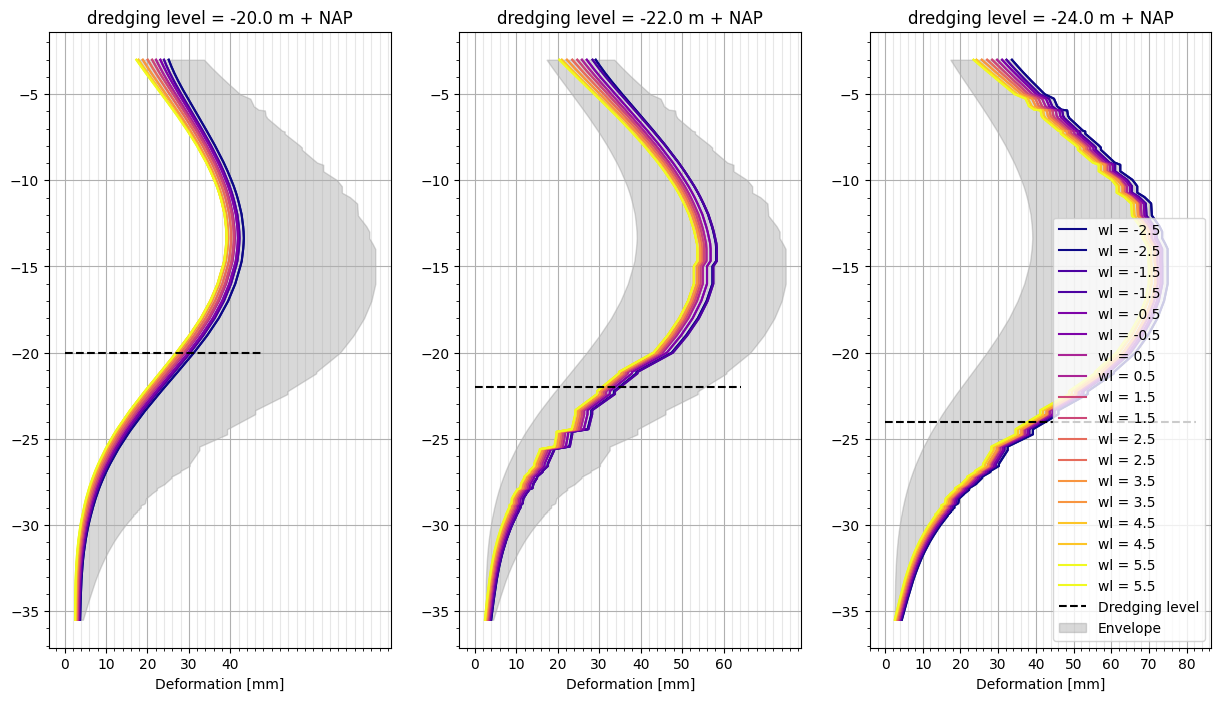

In [117]:

ps_log = pd.read_csv(f"Logs\\{run_name}\\_{run_name}_mainlog.csv", index_col=0)
U_total = pd.read_csv(f"logs\\{run_name}\\{run_name}_BP_U.csv", index_col=0)

phase = 8
U = pd.DataFrame()
for run in ps_log.index:
    wl = ps_log.loc[run, 'wl']
    d_level = ps_log.loc[run, 'd_level']
    U.loc[:, f"R_{run}"] = U_total.loc[:, f"U_{run_name}_P{phase}_R{run}"]
U_min = U.min(axis=1)
U_max = U.max(axis=1)

d_level = ps_log['d_level'].unique()[:3]
xticks_vals = np.arange(0, 81, 10)
fig, axes = plt.subplots(1, len(d_level), figsize=(5 * len(d_level), 8))
for i, d in enumerate(d_level):
    xmin, xmax = 0, U[[f"R_{run}" for run in ps_log[ps_log['d_level'] == d].index]].max().max()*1.1
    runs_temp = ps_log[ps_log['d_level'] == d].index
    colors = plt.cm.plasma(np.linspace(0, 1, len(runs_temp)))
    for j, run in enumerate(runs_temp):
        axes[i].plot(U[f"R_{run}"], U.index, color=colors[j], label=f"wl = {ps_log.loc[run, 'wl']}")
        axes[i].plot(U[f"R_{run}"], U.index, color=colors[j], label=f"wl = {ps_log.loc[run, 'wl']}")
    axes[i].hlines(d, xmin=xmin, xmax=xmax, colors='k', linestyles='--', label = f"Dredging level")
    axes[i].fill_betweenx(U.index, U_min, U_max, color='gray', alpha=0.3, label='Envelope')
    axes[i].set_title(f"dredging level = {d} m + NAP")
    axes[i].set_xlabel("Deformation [mm]")
    axes[i].set_xticks(xticks_vals[xticks_vals <= U[f"R_{run}"].max()*1.2])
    axes[i].minorticks_on()
    # axes[i].legend()
    axes[i].grid(True)
    axes[i].grid(which='minor', axis='x', alpha=0.3)
    # axes[i].set_xlim(0, U[[f"R_{run}" for run in runs_temp]].max().max()*1.1)

axes[i].legend()
    
# axes[0].set_ylabel("Depth [m + NAP]")
display(ps_log.head())

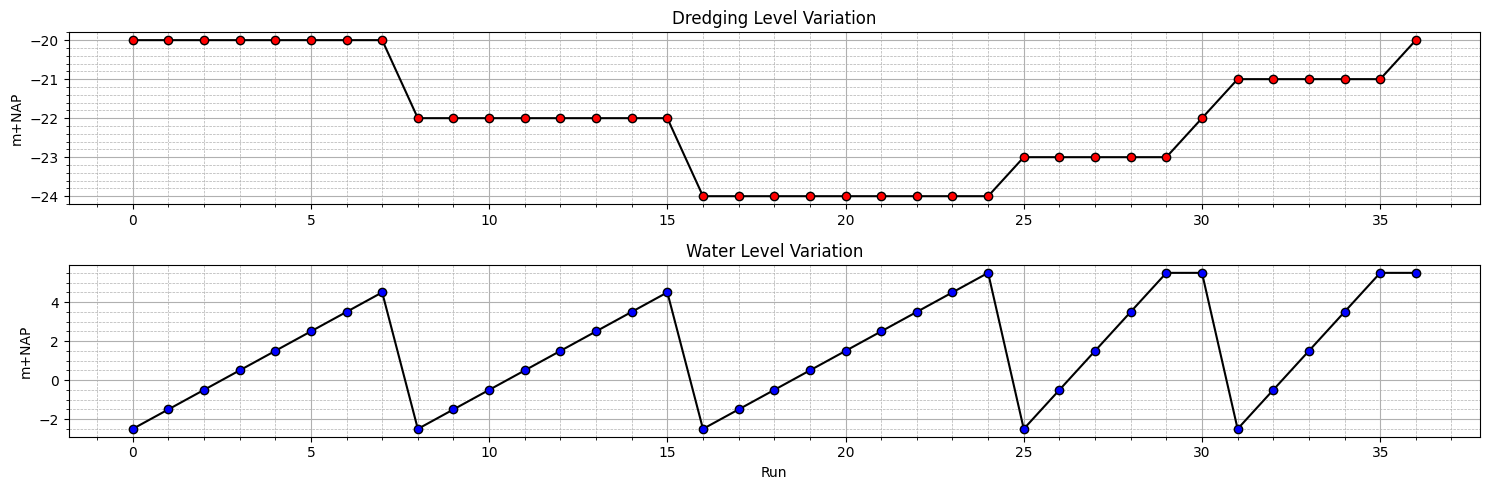

In [119]:
wl = ps_log['wl']
dl = ps_log['d_level']

fig,axes = plt.subplots(2,1, figsize=(15,5))
axes[0].plot(dl, 'k', marker='o', markerfacecolor='r')
axes[0].set_title('Dredging Level Variation')
axes[1].set_xlabel('Run')
axes[0].set_ylabel('m+NAP')

axes[1].plot(wl, 'k', marker='o', markerfacecolor='b')
axes[1].set_title('Water Level Variation')
axes[1].set_ylabel('m+NAP')

for ax in axes:
    ax.minorticks_on()
    ax.grid(True)
    ax.grid(which='minor', linestyle='--', linewidth='0.5')
    
plt.tight_layout()
plt.show()